In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re, os
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename, dirname
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_theme(style="white")
plt.rcdefaults()


pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

bigsize = (10, 7, ) # /2.54 = cm2inch
labelrot = 0

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    # e.g. "reconstructions_4096_avg/0_report.txt" -> "4096_avg"
    # e.g. "reconstructions_4096_last/0_report.txt" -> "4096_last"
    # keeping the pooling suffix (avg/last) in the key prevents the
    # 4096_avg and 4096_last folders from clobbering each other.
    dimensions = dirname(g).removeprefix("reconstructions_")
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=os.cpu_count()):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in tqdm(pool.map(_process_report, paths, chunksize=8)):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()
print("Parsing done.")

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

709537it [03:03, 3863.59it/s]


Parsing done.


709537it [03:23, 3485.11it/s]


Parsing done.


## Filters

In [4]:
# keep only same indices among all samples
# idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
# common_idx = set.intersection(*idx_per_dim)
# df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

# remove overtrained adapter
#df = df[(df.index.get_level_values('dim') != '128x4096_avg')]

# Take only validation set jsons into account
# df = df[(df.index.get_level_values('idx').astype(int) > 11504)]

# Take only valid jsons into account across all dimensions
# df = df[df.groupby(level='idx')['json_valid'].transform('all')]

In [5]:
df

item_index  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0              0   
                                                            10000      10000   
                                                            10002      10002   
                                                            10003      10003   
                                                            10004      10004   
...                                                                      ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998        9998   
                                                            9999        9999   
                                                            999          999   
                                                            99            99   
                                                            9              9   

                                                                                              json_path  \
dim                                                         idx                                           
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          ../rico-data/data/layouts/0.json   
                                                            10000  ../rico-data/data/layouts/10000.json   
                                                            10002  ../rico-data/data/layouts/10002.json   
                                                            10003  ../rico-data/data/layouts/10003.json   
                                                            10004  ../rico-data/data/layouts/10004.json   
...                                                                                                 ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998    ../rico-data/data/layouts/9998.json   
                                                            9999    ../rico-data/data/layouts/9999.json   
                                                            999      ../rico-data/data/layouts/999.json   
                                                            99        ../rico-data/data/layouts/99.json   
                                                            9          ../rico-data/data/layouts/9.json   

                                                                                      embedding_path  \
dim                                                         idx                                        
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          embeddings_128x4096_avg/0.npz   
                                                            10000  embeddings_128x4096_avg/10000.npz   
                                                            10002  embeddings_128x4096_avg/10002.npz   
                                                            10003  embeddings_128x4096_avg/10003.npz   
                                                            10004  embeddings_128x4096_avg/10004.npz   
...                                                                                              ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998      embeddings_8x4096_avg/9998.npz   
                                                            9999      embeddings_8x4096_avg/9999.npz   
                                                            999        embeddings_8x4096_avg/999.npz   
                                                            99          embeddings_8x4096_avg/99.npz   
                                                            9            embeddings_8x4096_avg/9.npz   

                                                                  json_valid  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0           True   
                                        

item_index  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0              0   
                                                            10000      10000   
                                                            10002      10002   
                                                            10003      10003   
                                                            10004      10004   
...                                                                      ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998        9998   
                                                            9999        9999   
                                                            999          999   
                                                            99            99   
                                                            9              9   

                                                                                              json_path  \
dim                                                         idx                                           
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          ../rico-data/data/layouts/0.json   
                                                            10000  ../rico-data/data/layouts/10000.json   
                                                            10002  ../rico-data/data/layouts/10002.json   
                                                            10003  ../rico-data/data/layouts/10003.json   
                                                            10004  ../rico-data/data/layouts/10004.json   
...                                                                                                 ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998    ../rico-data/data/layouts/9998.json   
                                                            9999    ../rico-data/data/layouts/9999.json   
                                                            999      ../rico-data/data/layouts/999.json   
                                                            99        ../rico-data/data/layouts/99.json   
                                                            9          ../rico-data/data/layouts/9.json   

                                                                                      embedding_path  \
dim                                                         idx                                        
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0          embeddings_128x4096_avg/0.npz   
                                                            10000  embeddings_128x4096_avg/10000.npz   
                                                            10002  embeddings_128x4096_avg/10002.npz   
                                                            10003  embeddings_128x4096_avg/10003.npz   
                                                            10004  embeddings_128x4096_avg/10004.npz   
...                                                                                              ...   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b    9998      embeddings_8x4096_avg/9998.npz   
                                                            9999      embeddings_8x4096_avg/9999.npz   
                                                            999        embeddings_8x4096_avg/999.npz   
                                                            99          embeddings_8x4096_avg/99.npz   
                                                            9            embeddings_8x4096_avg/9.npz   

                                                                  json_valid  \
dim                                                         idx                
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b 0           True   
                                        

In [6]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [7]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


In [8]:
import re
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.container import BarContainer


FIRST_NUMBER_PRIORITY = {
    4096: 0,
    4: 1,
    8: 2,
    128: 3,
}


def first_number_sort_key(value):
    text = str(value)
    match = re.search(r"\d+", text)

    if match is None:
        return 2, float("inf"), text.casefold()

    first_number = int(match.group())

    if first_number in FIRST_NUMBER_PRIORITY:
        return (
            0,
            FIRST_NUMBER_PRIORITY[first_number],
            text.casefold(),
        )

    return (
        1,
        first_number,
        text.casefold(),
    )


def plot_bool_grouped(
    df: pd.DataFrame,
    bool_cols: list,
    by: str,
    as_percentage: bool = True,
    xlabel: str | None = None,
    title: str | None = None,
    show_legend: bool = True,
):
    data = (
        df.reset_index()
        if by in df.index.names and by not in df.columns
        else df.copy()
    )

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem().fillna(0) * 100
        default_xlabel = "Share True (%)"
        value_format = "%.1f"
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std().fillna(0)
        default_xlabel = "Count True"
        value_format = "%.0f"

    sorted_labels = sorted(
        grouped.index,
        key=first_number_sort_key,
    )

    grouped = grouped.reindex(sorted_labels)
    errors = errors.reindex(sorted_labels)

    ax = grouped.plot(
        kind="barh",
        xerr=errors,
        capsize=4,
        figsize=bigsize,
        legend=show_legend,
    )

    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(
                container,
                fmt=value_format,
                padding=3,
                fontsize=8,
            )

    ax.set_xlabel(
        xlabel if xlabel is not None else default_xlabel
    )
    ax.set_ylabel(by)
    ax.set_title(
        title
        if title is not None
        else f'True distribution grouped by "{by}"'
    )
    ax.tick_params(
        axis="y",
        labelrotation=labelrot,
    )

    ax.invert_yaxis()

    if show_legend:
        ax.legend(
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
        )

    plt.tight_layout()
    plt.show()

def show_stats(column: str, by: str = "dim"):
    global df

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

    # "dim" is an index level (df has a ("dim", "idx") MultiIndex), so it
    # cannot be addressed as df["dim"] -- fall back to the index level.
    labels = (
        df.index.get_level_values(by)
        if by in df.index.names and by not in df.columns
        else df[by]
    )
    label_values = pd.Series(labels, index=df.index)

    sorted_labels = sorted(
        label_values.dropna().unique(),
        key=first_number_sort_key,
    )

    boxplot_data = [
        df.loc[(label_values == label).to_numpy(), column].dropna()
        for label in sorted_labels
    ]

    fig, ax = plt.subplots(figsize=bigsize)

    ax.boxplot(
        boxplot_data,
        tick_labels=sorted_labels,
        showfliers=False,
        vert=False,
    )

    ax.set_xlabel(column)
    ax.set_ylabel(by)
    ax.set_title(f'{column} grouped by "{by}"')
    ax.tick_params(
        axis="y",
        labelrotation=labelrot,
    )

    ax.invert_yaxis()

    plt.tight_layout()
    plt.show()

    grouped_column = df.groupby(
        by,
        sort=False,
    )[column]

    desc_stats = grouped_column.describe()
    desc_stats["median"] = grouped_column.median()
    desc_stats["IQR"] = (
        grouped_column.quantile(0.75)
        - grouped_column.quantile(0.25)
    )

    desc_stats = desc_stats.reindex(sorted_labels)

    print(desc_stats)


In [9]:
df.groupby('dim').count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260,66260
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261,66261


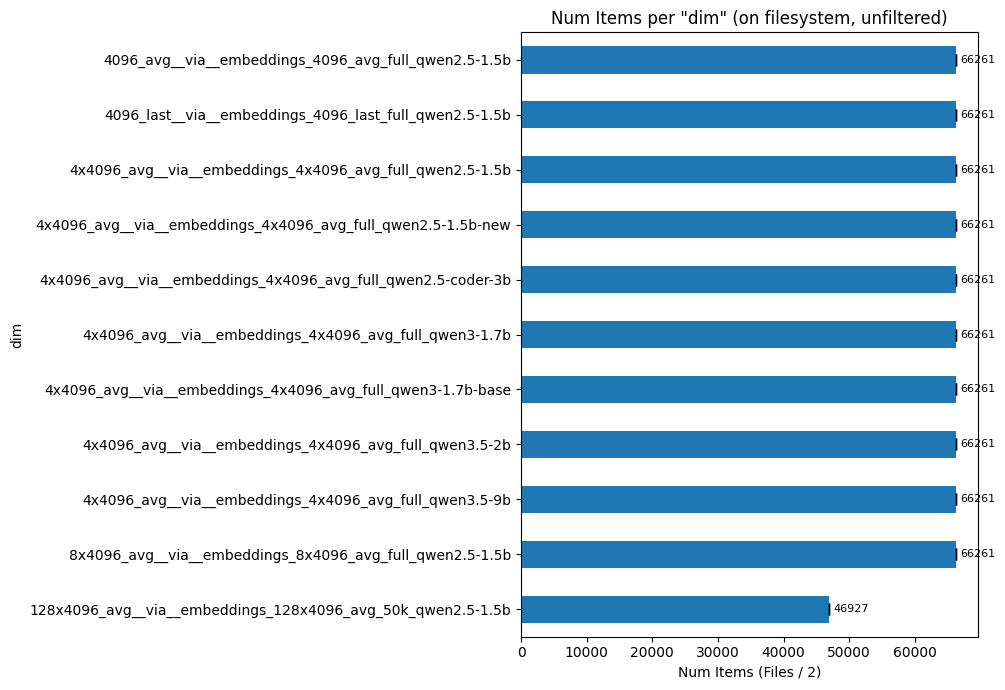

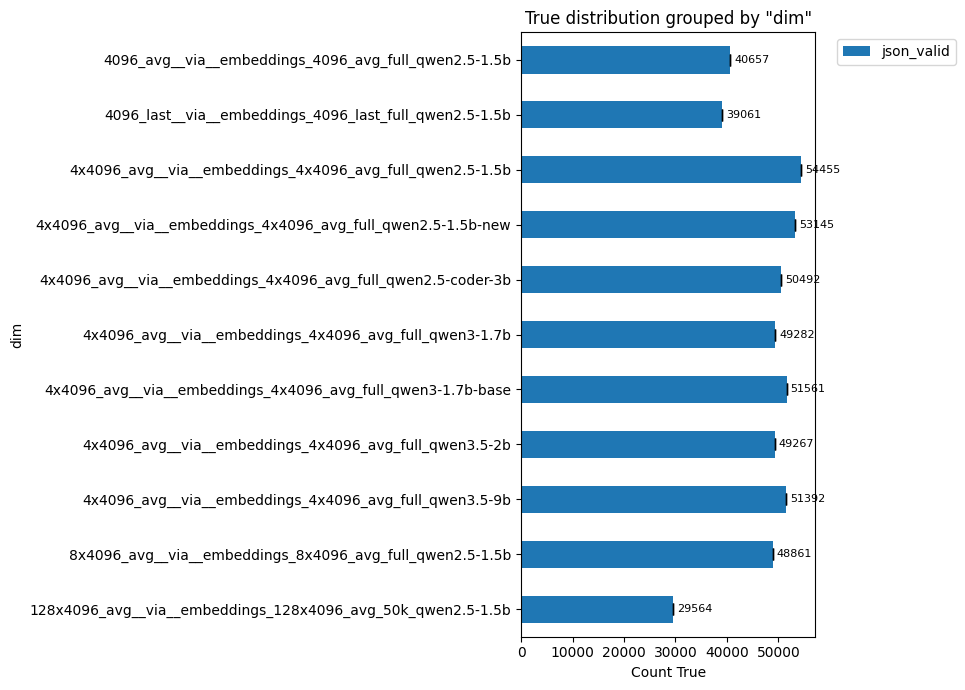

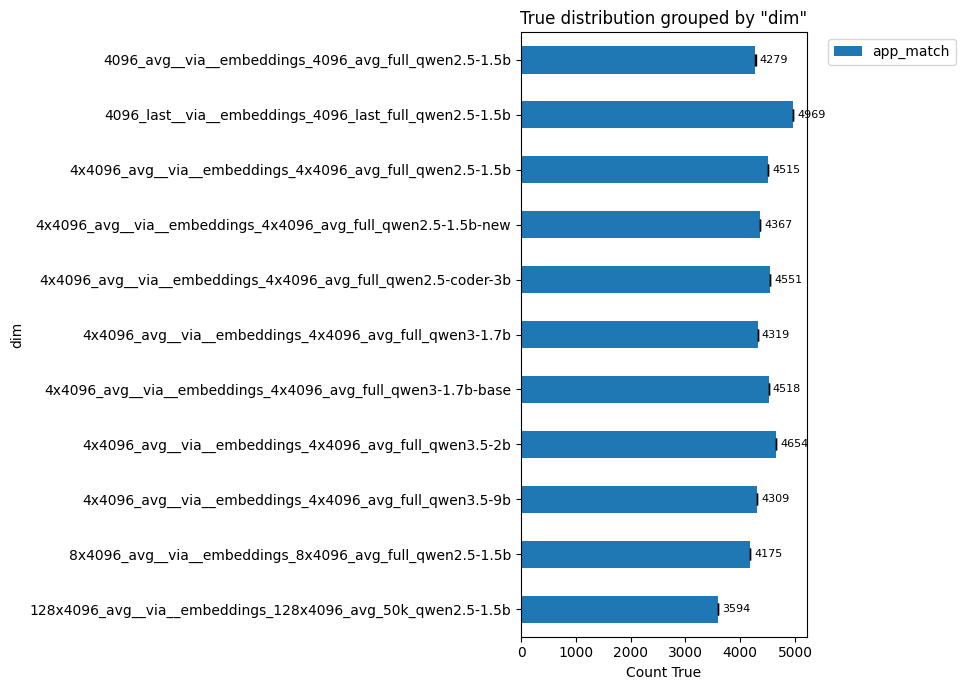

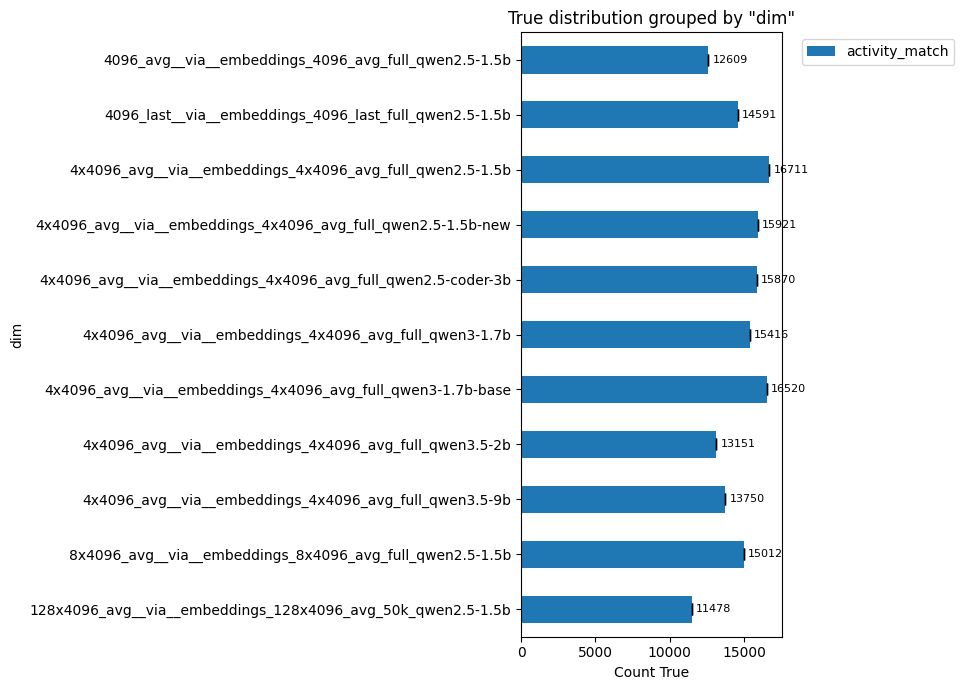

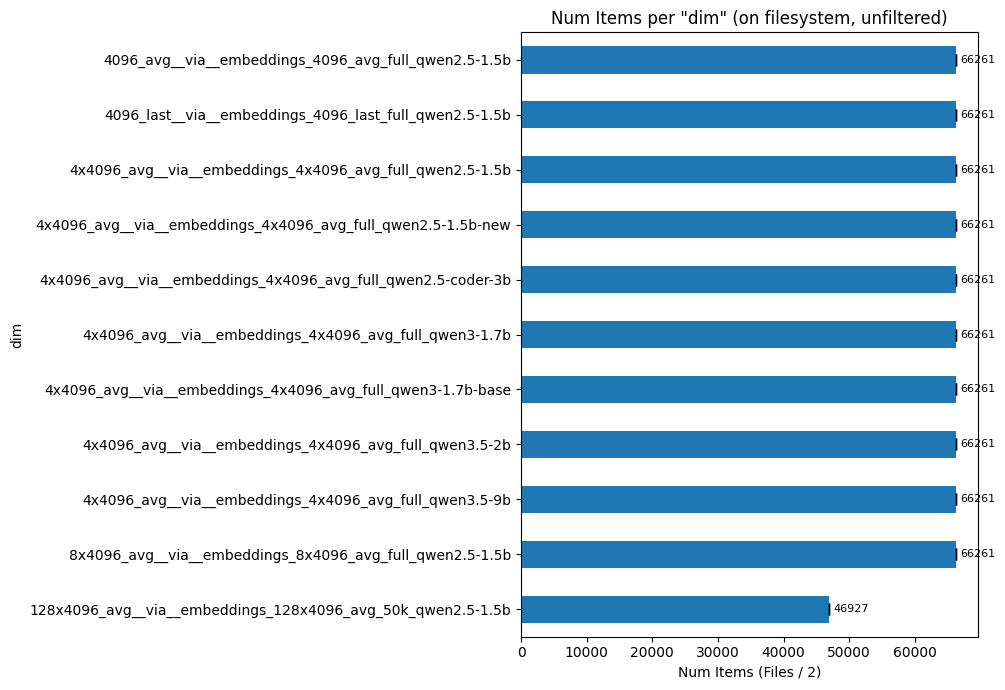

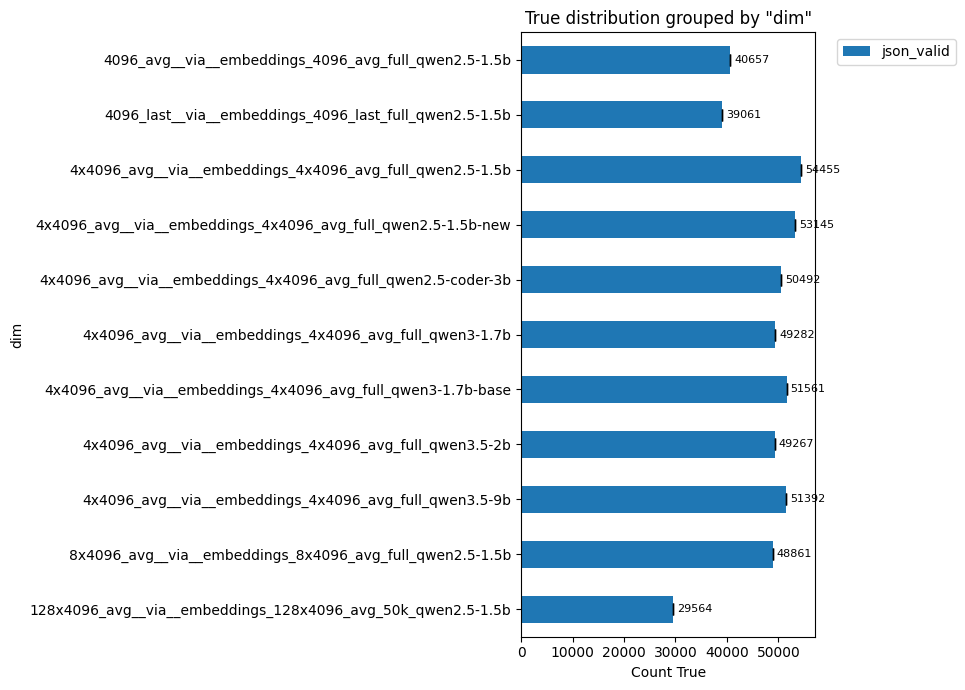

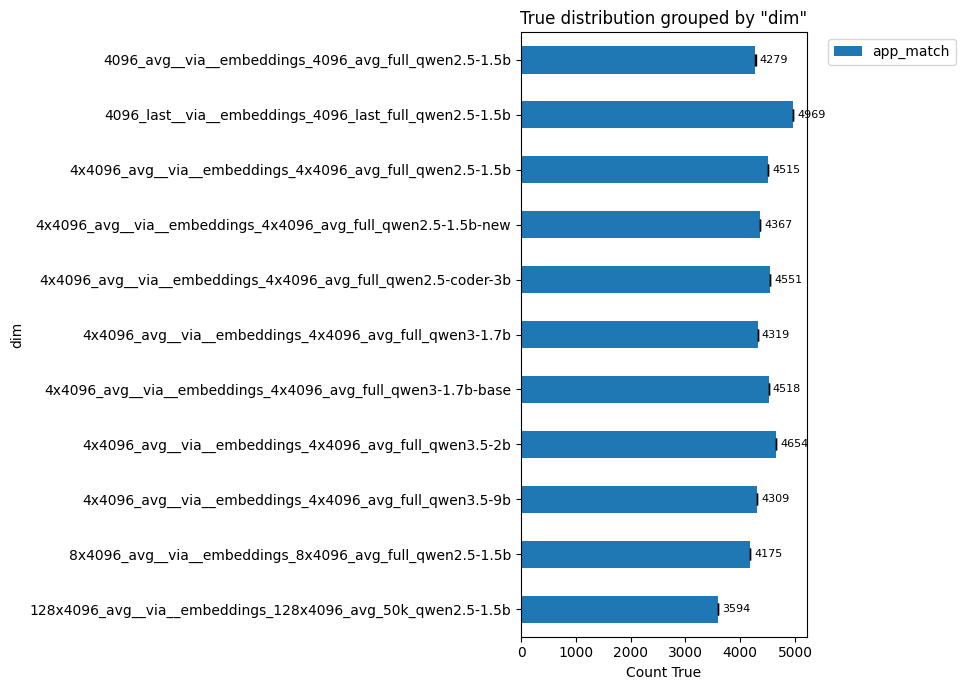

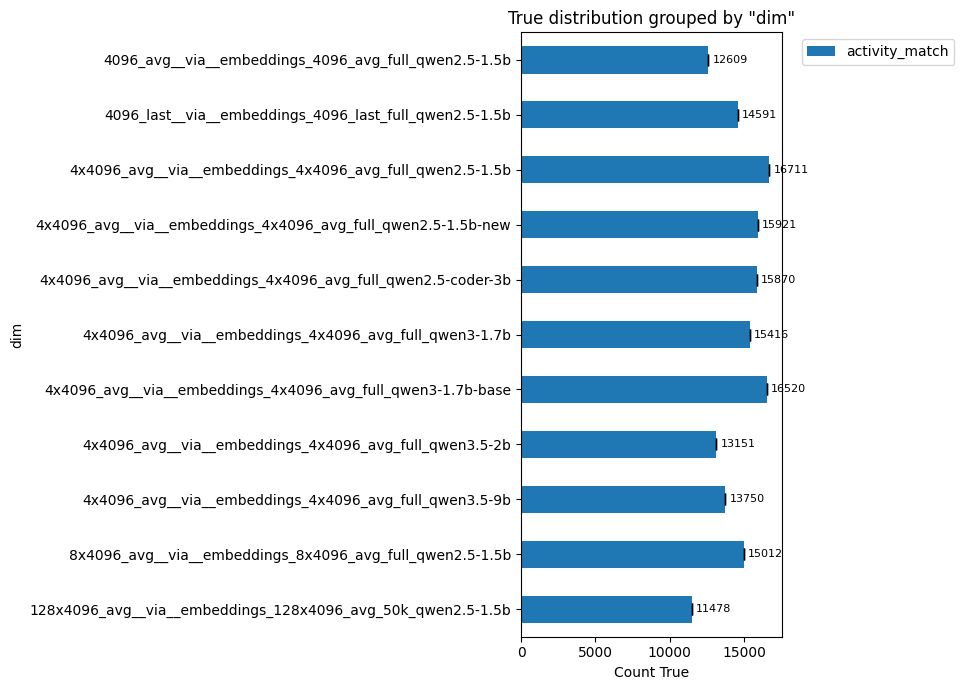

In [10]:
file_counts_df = (
    pd.Series(
        {
            directory.removeprefix("reconstructions_"):
                len(glob(f"{directory}/*")) // 2
            for directory in glob("reconstructions_*")
        },
        name="num_items",
    )
    .rename_axis("dim")
    .reset_index()
)


plot_bool_grouped(
    file_counts_df,
    ["num_items"],
    by="dim",
    as_percentage=False,
    xlabel="Num Items (Files / 2)",
    title='Num Items per "dim" (on filesystem, unfiltered)',
    show_legend=False,
)

plot_bool_grouped(
    df,
    ["json_valid"],
    by="dim",
    as_percentage=False,
)

plot_bool_grouped(
    df,
    ["app_match"],
    by="dim",
    as_percentage=False,
)

plot_bool_grouped(
    df,
    ["activity_match"],
    by="dim",
    as_percentage=False,
)

## Boxplot: Sequence Similarity

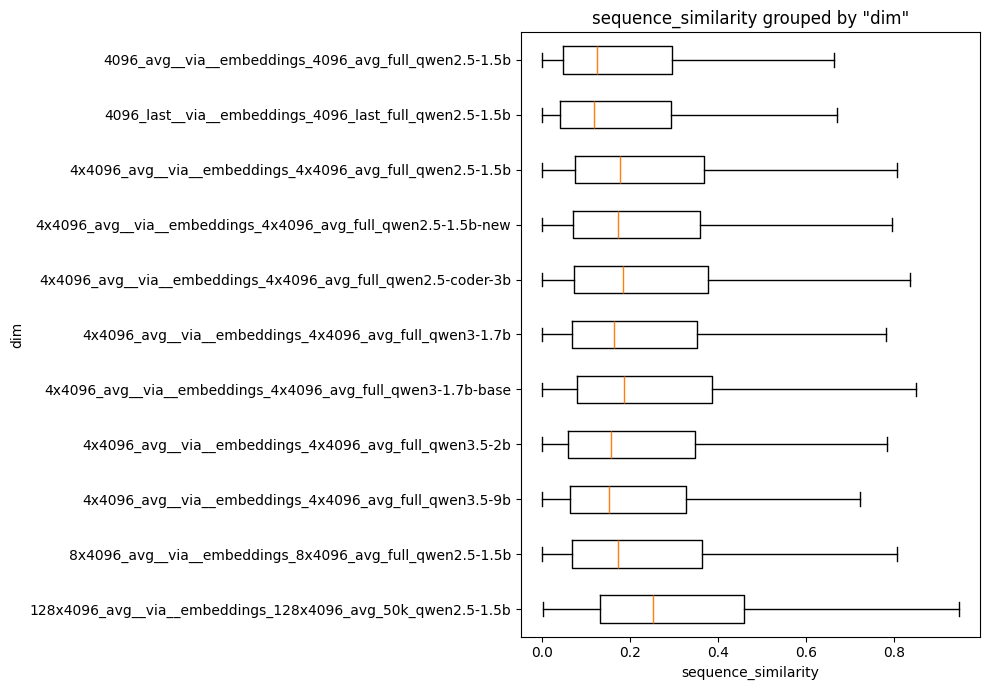

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

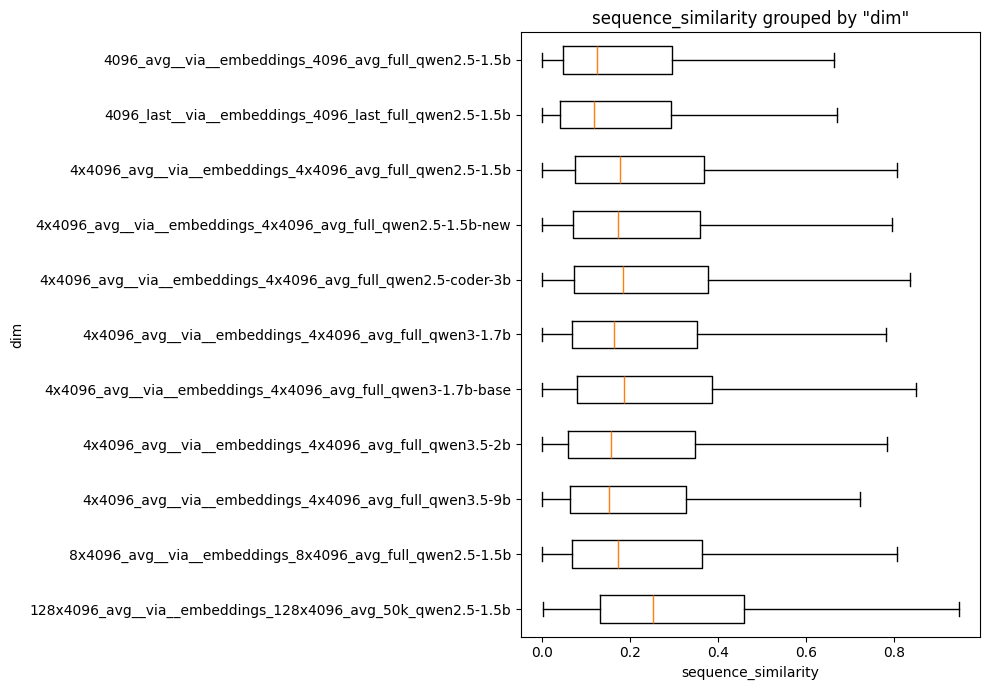

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [11]:
show_stats('sequence_similarity')

## Boxplot: Levenshtein Distance

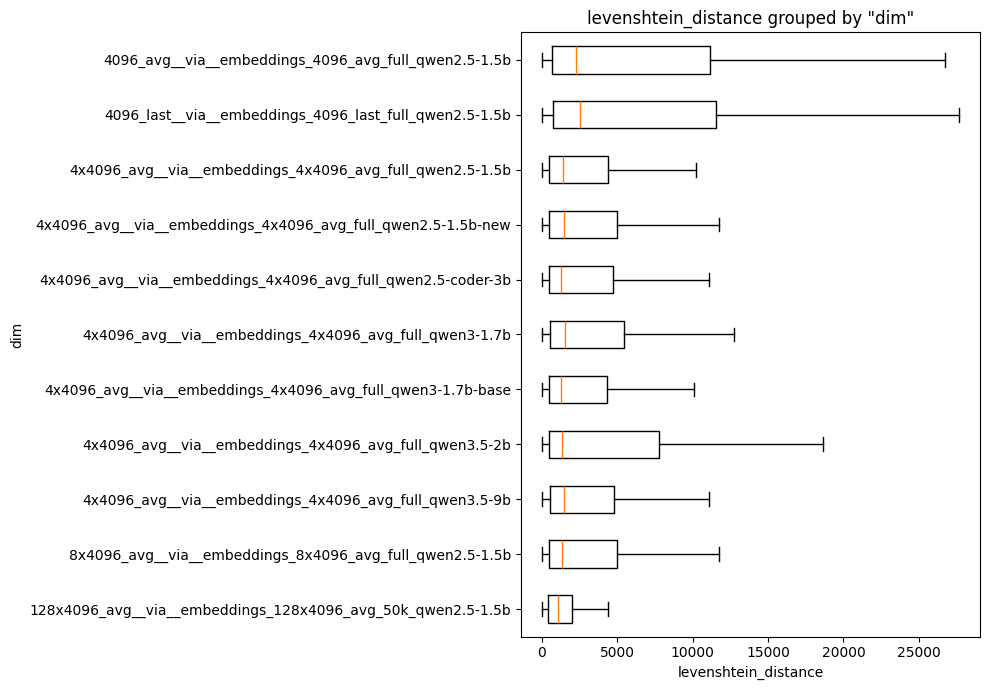

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

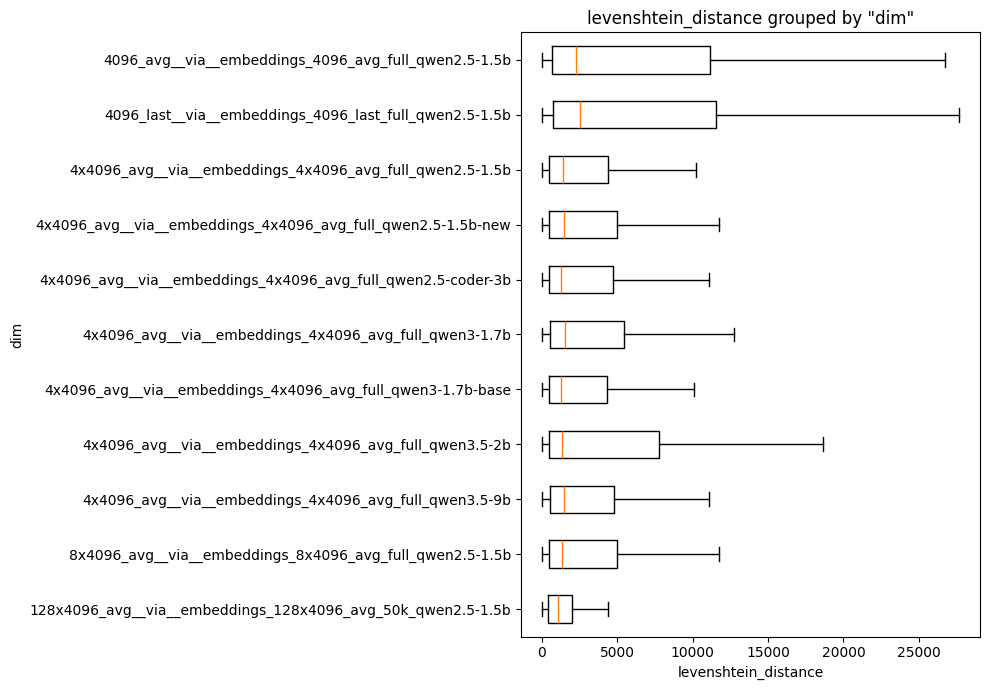

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [12]:
show_stats('levenshtein_distance')

## Boxplot: Levenshtein Similarity

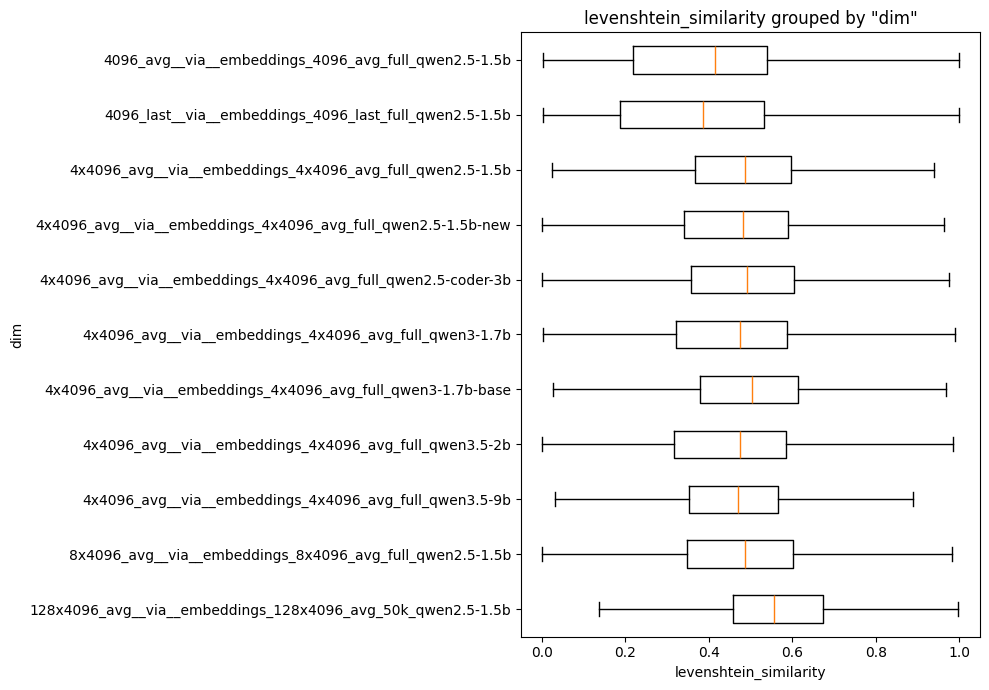

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

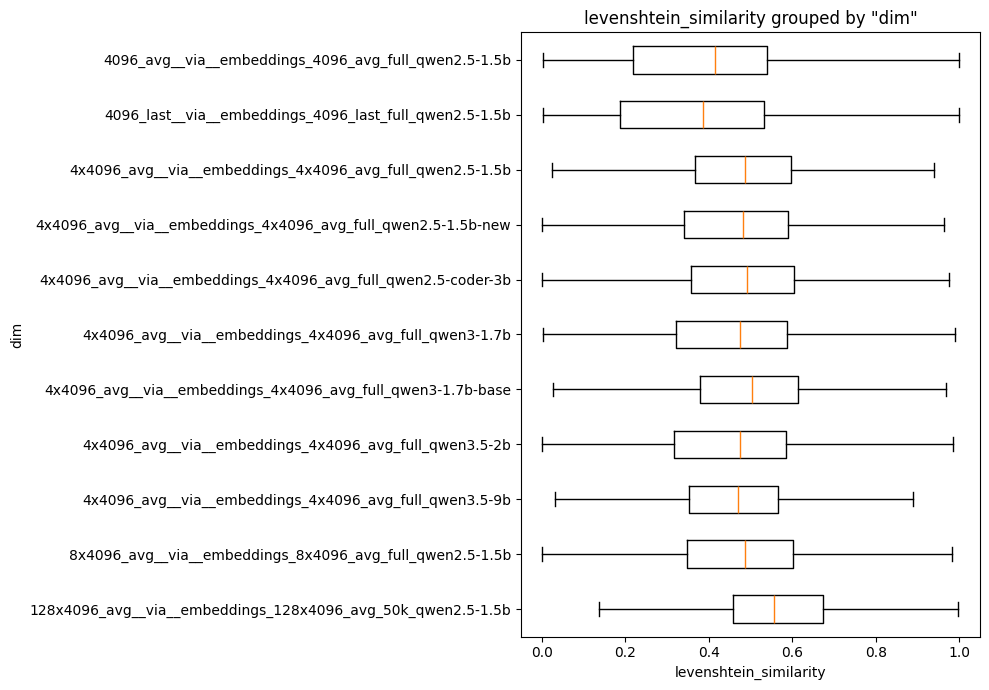

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [13]:
show_stats('levenshtein_similarity')

## Boxplot: Class Accuracy

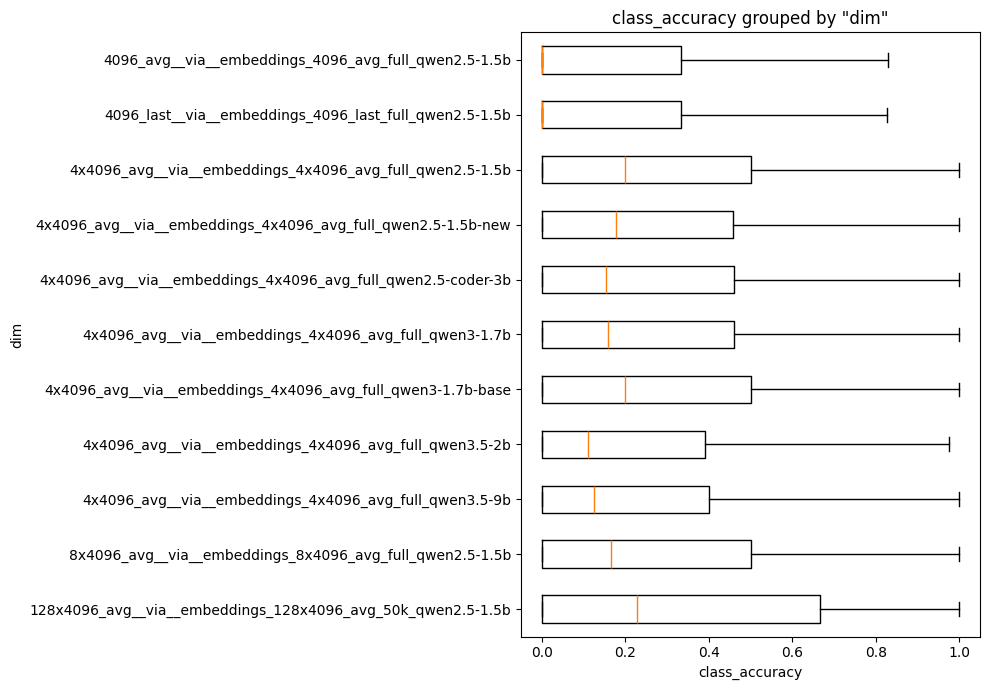

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

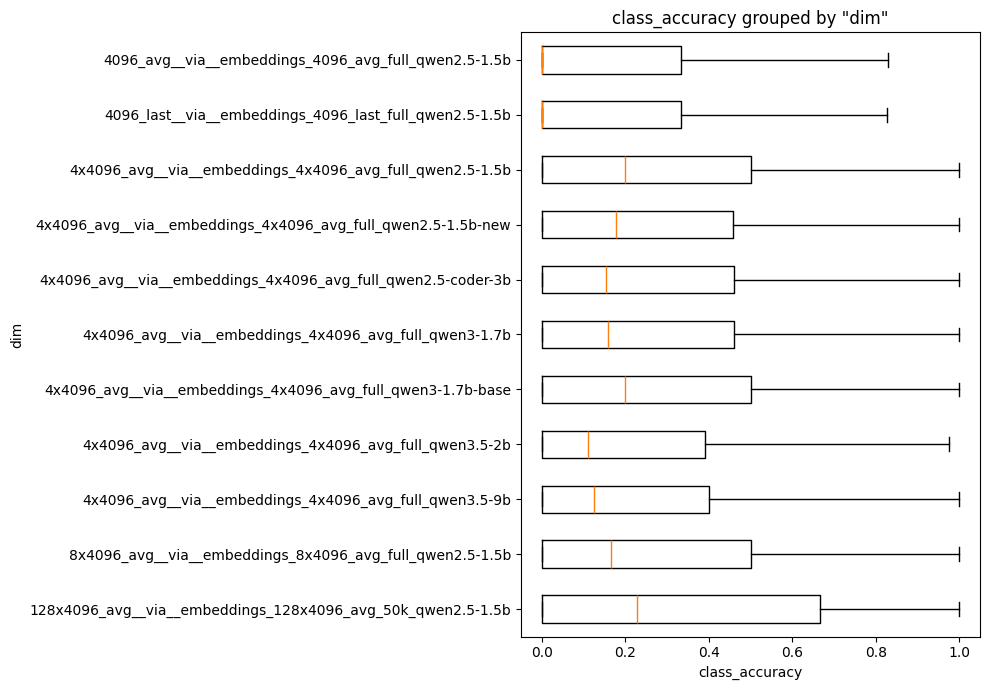

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [14]:
show_stats('class_accuracy')

## Boxplot: Average Bounds IoU

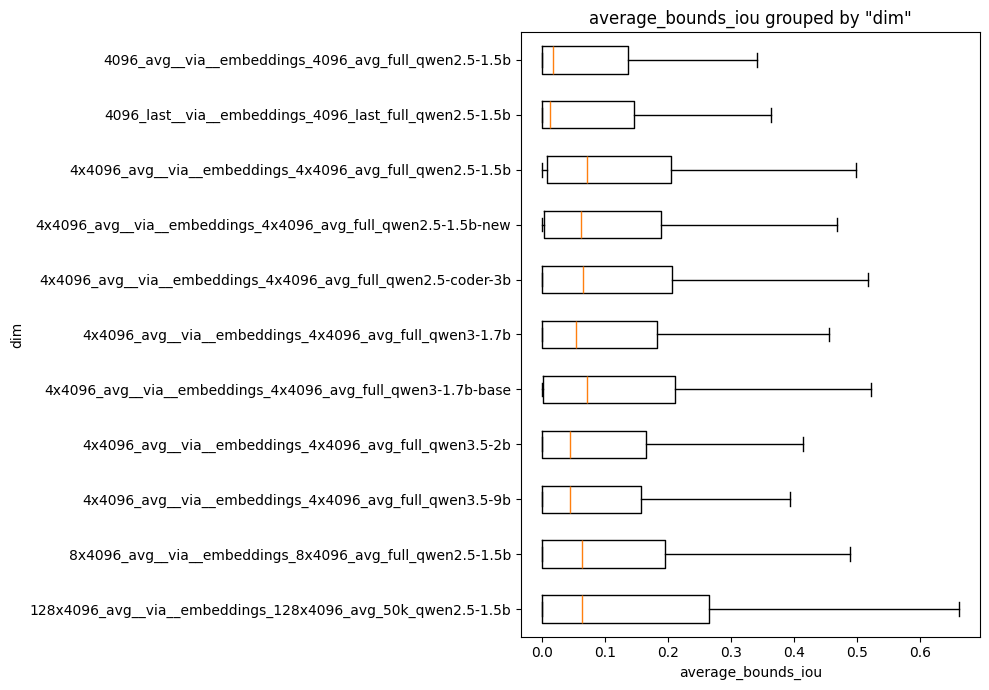

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

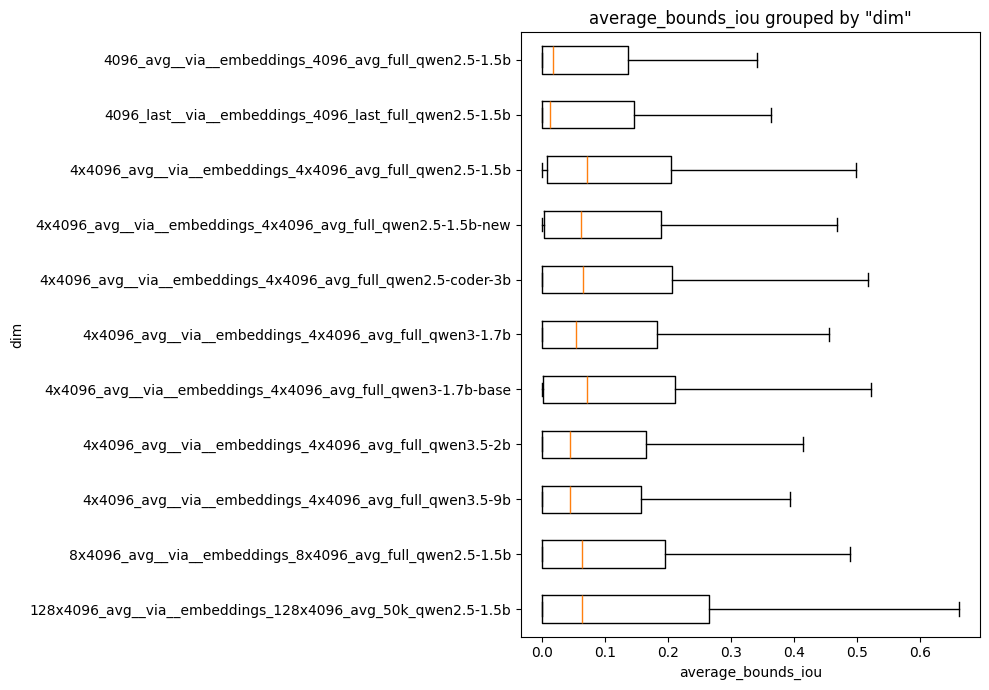

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [15]:
show_stats('average_bounds_iou')

## Repaired JSON

In [16]:
# --- Repair pass ---------------------------------------------------------------
#
# The reports on disk only hold the *strict* evaluation: a prediction that
# does not parse counts as 0 components, 0 class accuracy, 0 IoU. Here the raw
# predictions (`*_reconstructed.json`) are loaded again, repaired with
# json_repair, and scored with exactly the same functions that produced the
# reports: reconstruction_metrics.score_against_ground_truth(), shared with
# 3_json_reconstruction_par.py.
#
# The strict columns are left untouched; everything repaired is added
# alongside under the "_repaired" suffix -- otherwise the numbers here would
# no longer be comparable to the ones in the reports.

from concurrent.futures import ProcessPoolExecutor

import repair_rescore

# ---------------------------------------------------------------- Switches ---
# Collapse repetition loops in the LLM output: a degenerate generation does
# not stop after the screen, it repeats the same component (or the same short
# cycle) until the token budget runs out. Every copy shifts the paired
# comparison with the ground truth by one position, so exact-duplicate
# sibling subtrees are collapsed onto a single one, recursively.
COLLAPSE_LOOPS = True

# Only rescore the broken JSONs. For a prediction that already parsed, the
# repair is a no-op -- the strict value *is* the repaired one there. But: a
# valid JSON can be looped too (roughly one in five rows), and this pass then
# never sees it. So True = fast (only the invalid rows), False = complete, at
# roughly 190 rows/s on 14 cores.
ONLY_INVALID = False

MAX_WORKERS = None   # None -> os.cpu_count()
CHUNKSIZE = 16

tasks = repair_rescore.build_tasks(df, only_invalid=ONLY_INVALID)
n_rows = sum(len(entries) for _, _, entries in tasks)

print(
    f"Rescoring {n_rows} of {len(df)} rows "
    f"({len(tasks)} screens, COLLAPSE_LOOPS={COLLAPSE_LOOPS})"
)

Rescoring 709537 of 709537 rows (66261 screens, COLLAPSE_LOOPS=True)
Rescoring 709537 of 709537 rows (66261 screens, COLLAPSE_LOOPS=True)


In [17]:
# Processes, not threads: cleaning the Rico ground truth, parsing, and the
# Levenshtein distance are CPU-bound and would otherwise block each other on
# the GIL.
#
# One task is a screen index together with every dimension that needs it --
# the ground truth is loaded once per screen instead of once per row.

rows = []

if tasks:
    with ProcessPoolExecutor(
        max_workers=MAX_WORKERS,
        initializer=repair_rescore.init_worker,
        initargs=(COLLAPSE_LOOPS,),
    ) as pool:
        for result in tqdm(
            pool.map(repair_rescore.rescore_item, tasks, chunksize=CHUNKSIZE),
            total=len(tasks),
            desc="repair + rescore",
        ):
            rows.extend(result)

df_repaired = (
    pd.DataFrame(rows).set_index(["dim", "idx"])
    if rows
    else pd.DataFrame(index=df.index[:0])
)

if "rescore_error" in df_repaired.columns:
    n_failed = int(df_repaired["rescore_error"].notna().sum())
    if n_failed:
        print(f"{n_failed} rows without a result (prediction file missing)")

df_repaired.head()

repair + rescore: 100%|██████████| 66261/66261 [13:19<00:00, 82.84it/s] 


1 rows without a result (prediction file missing)


,,json_valid_repaired,json_repair_used,components_collapsed,levenshtein_distance_repaired,levenshtein_similarity_repaired,app_match_repaired,activity_match_repaired,component_count_gt_repaired,component_count_pred_repaired,class_accuracy_repaired,average_bounds_iou_repaired,rescore_error
dim,idx,,,,,,,,,,,,
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b,0,True,False,0.0,19.0,0.886905,False,True,1.0,1.0,1.0,1.000000,NaN
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b,0,True,False,0.0,19.0,0.887574,False,True,1.0,1.0,1.0,1.000000,NaN
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b,0,True,False,0.0,16.0,0.910112,False,True,1.0,1.0,1.0,0.929293,NaN
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b,0,True,False,0.0,21.0,0.875000,False,True,1.0,1.0,1.0,1.000000,NaN
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new,0,True,False,0.0,32.0,0.809524,False,False,1.0,1.0,1.0,0.929293,NaN


repair + rescore:  72%|███████▏  | 47713/66261 [12:45<04:30, 68.59it/s] 

In [18]:
# Carry the repaired columns for *all* rows, not just the rescored ones:
# where a row was not rescored, the strict value already is the repaired one.
# Otherwise every plot below would be comparing two different populations.

REPAIRED_TWIN = {
    "json_valid_repaired":             "json_valid",
    "levenshtein_distance_repaired":   "levenshtein_distance",
    "levenshtein_similarity_repaired": "levenshtein_similarity",
    "app_match_repaired":              "app_match",
    "activity_match_repaired":         "activity_match",
    "component_count_gt_repaired":     "component_count_gt",
    "component_count_pred_repaired":   "component_count_pred",
    "class_accuracy_repaired":         "class_accuracy",
    "average_bounds_iou_repaired":     "average_bounds_iou",
}

# The order-free metrics (class_unordered_*, class_level_*, matched_iou) were
# added after the reports on disk were written, so -- unlike every column above
# -- they have no strict twin in `df` to fall back on. Both halves come out of
# the rescore pass, which is why they are carried separately below and why a
# row that was not rescored stays NaN rather than silently borrowing a value.
from reconstruction_metrics import UNORDERED_METRIC_KEYS

_empty = pd.Series(index=df.index, dtype="object")

for repaired_col, strict_col in REPAIRED_TWIN.items():
    values = (
        df_repaired[repaired_col].reindex(df.index)
        if repaired_col in df_repaired.columns
        else _empty
    )
    df[repaired_col] = values.where(values.notna(), df[strict_col])

for key in UNORDERED_METRIC_KEYS:
    for col in (key, f"{key}_repaired"):
        df[col] = pd.to_numeric(
            df_repaired[col].reindex(df.index)
            if col in df_repaired.columns
            else _empty,
            errors="coerce",
        )

n_unscored = int(df["class_unordered_f1"].isna().sum())
if n_unscored:
    print(
        f"{n_unscored} of {len(df)} rows carry no order-free score -- they were "
        "not part of the rescore pass. Set ONLY_INVALID = False above for full "
        "coverage."
    )


# Only ever defined for the rescored rows; everywhere else is "not repaired"
# resp. "nothing collapsed" by construction.
for extra_col, default in (("json_repair_used", False), ("components_collapsed", 0)):
    values = (
        df_repaired[extra_col].reindex(df.index)
        if extra_col in df_repaired.columns
        else _empty
    )
    df[extra_col] = values.where(values.notna(), default)


# ---------------------------------------------------------- Summary table ---
summary_cols = [
    "json_valid", "json_valid_repaired", "json_repair_used",
    "app_match", "app_match_repaired",
    "activity_match", "activity_match_repaired",
    "class_accuracy", "class_accuracy_repaired",
    "average_bounds_iou", "average_bounds_iou_repaired",
    "levenshtein_similarity", "levenshtein_similarity_repaired",
    "component_count_gt", "component_count_pred", "component_count_pred_repaired",
    "components_collapsed",
] + [
    col
    for key in UNORDERED_METRIC_KEYS
    for col in (key, f"{key}_repaired")
]

summary = (
    df[summary_cols]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
    .groupby(df.index.get_level_values("dim"))
    .mean()
    .rename_axis("dim")
)
summary.insert(0, "n", df.groupby("dim").size())
summary = summary.reindex(sorted(summary.index, key=first_number_sort_key))

print(summary.T.to_string(float_format=lambda v: f"{v:.4f}"))

dim                              4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b  4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b  4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b  4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b  4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base  4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b  4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b  8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b  128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b
n                                                                          66261.0000                                              66261.0000                                                66261.0000                                                    66261.0000                                                    66261.0000     

### Repaired: JSON Valid / App Match / Activity Match

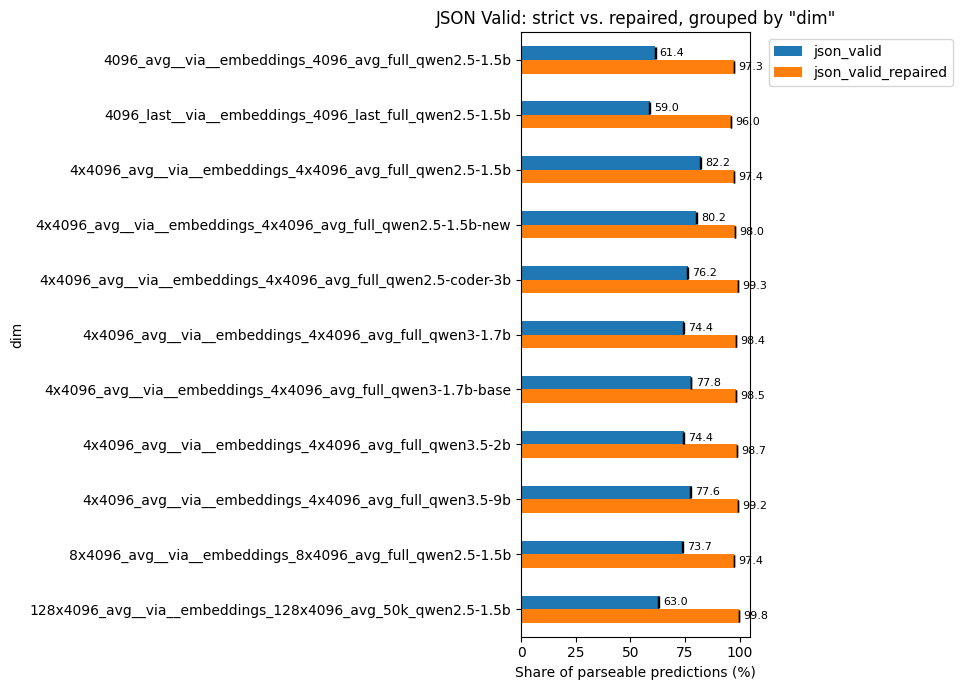

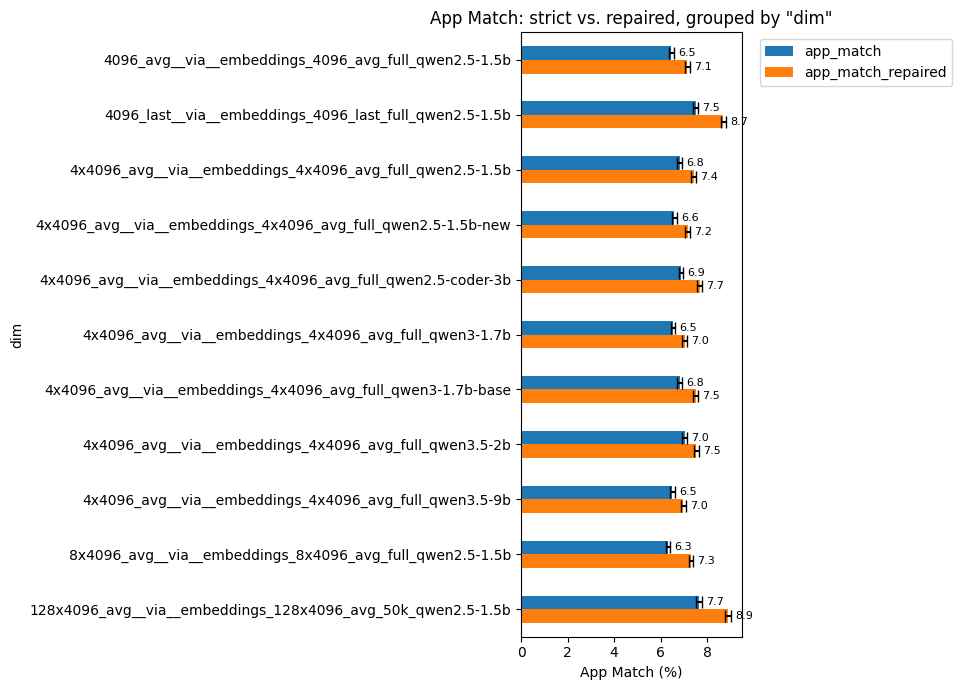

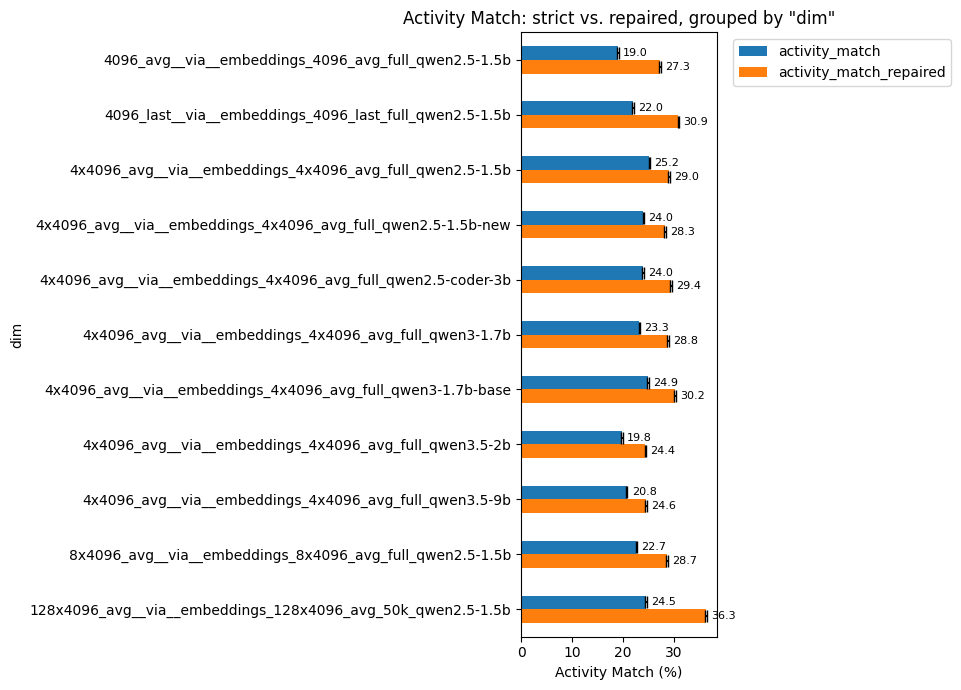

In [19]:
# Strict vs. repaired side by side -- the same function as above, just with
# both columns in one call.

plot_bool_grouped(
    df,
    ["json_valid", "json_valid_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="Share of parseable predictions (%)",
    title='JSON Valid: strict vs. repaired, grouped by "dim"',
)

plot_bool_grouped(
    df,
    ["app_match", "app_match_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="App Match (%)",
    title='App Match: strict vs. repaired, grouped by "dim"',
)

plot_bool_grouped(
    df,
    ["activity_match", "activity_match_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="Activity Match (%)",
    title='Activity Match: strict vs. repaired, grouped by "dim"',
)

### Boxplot: Class Accuracy (strict vs. repaired)

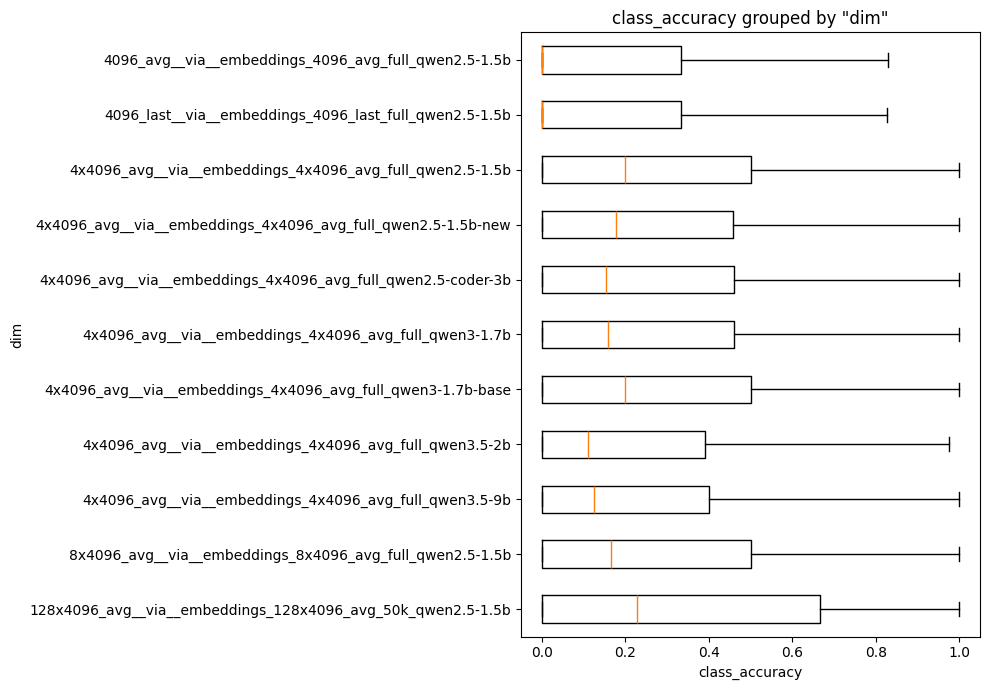

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

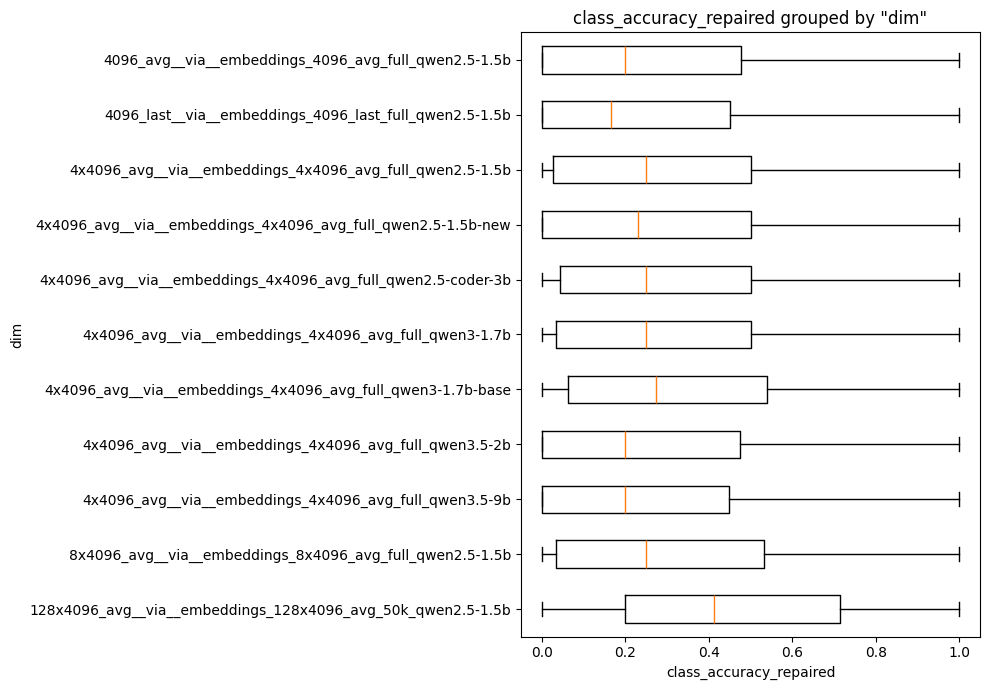

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [20]:
show_stats('class_accuracy')
show_stats('class_accuracy_repaired')

### Boxplot: Average Bounds IoU (strict vs. repaired)

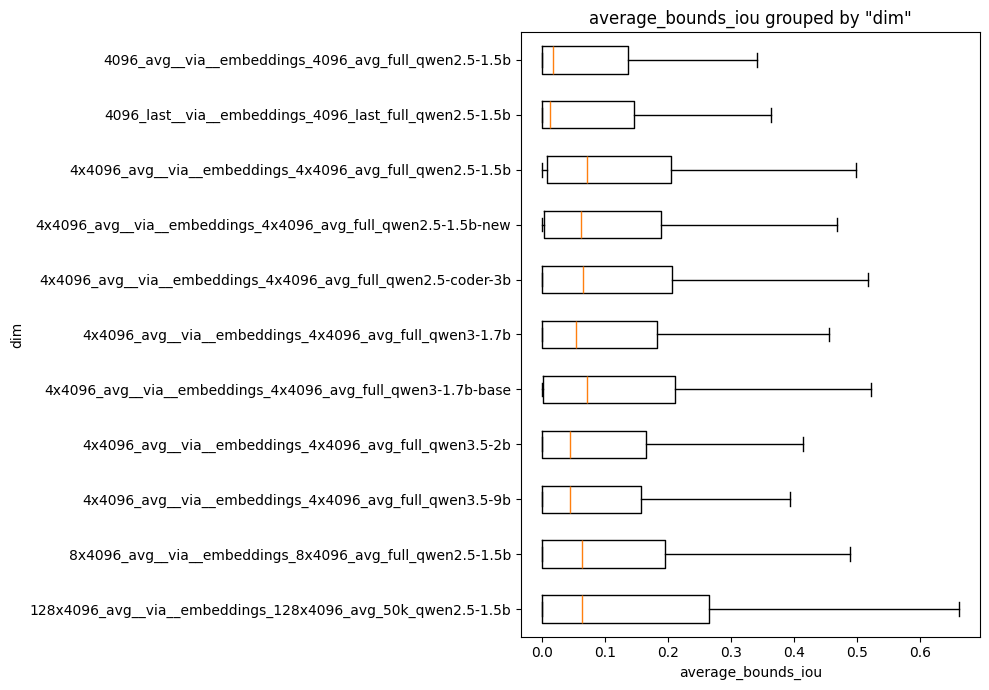

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

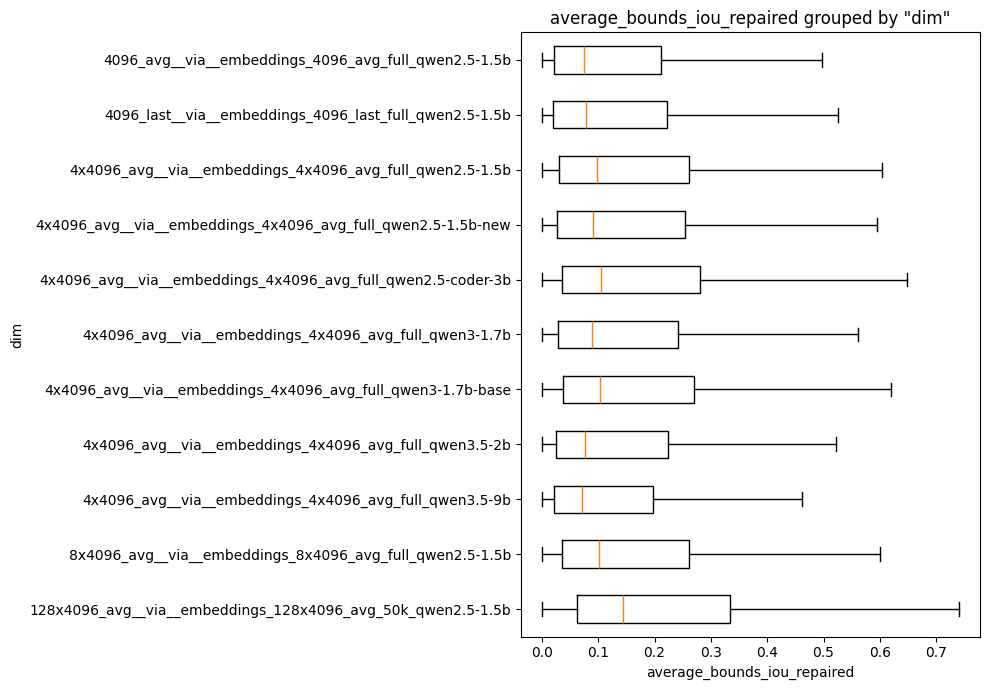

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [21]:
show_stats('average_bounds_iou')
show_stats('average_bounds_iou_repaired')

### Boxplot: Levenshtein Similarity (strict vs. repaired)

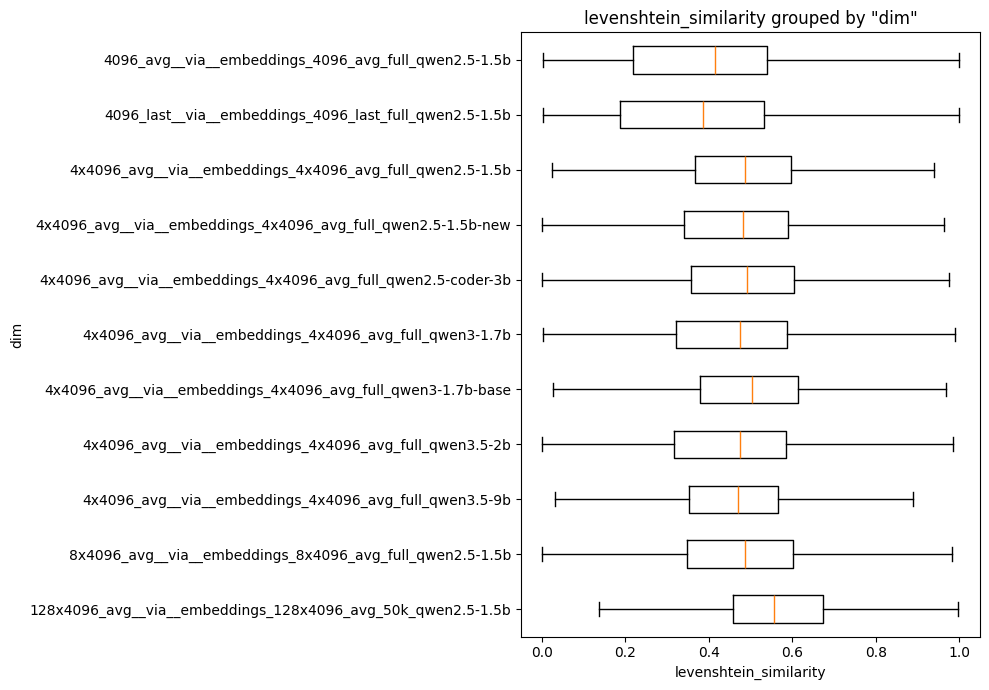

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

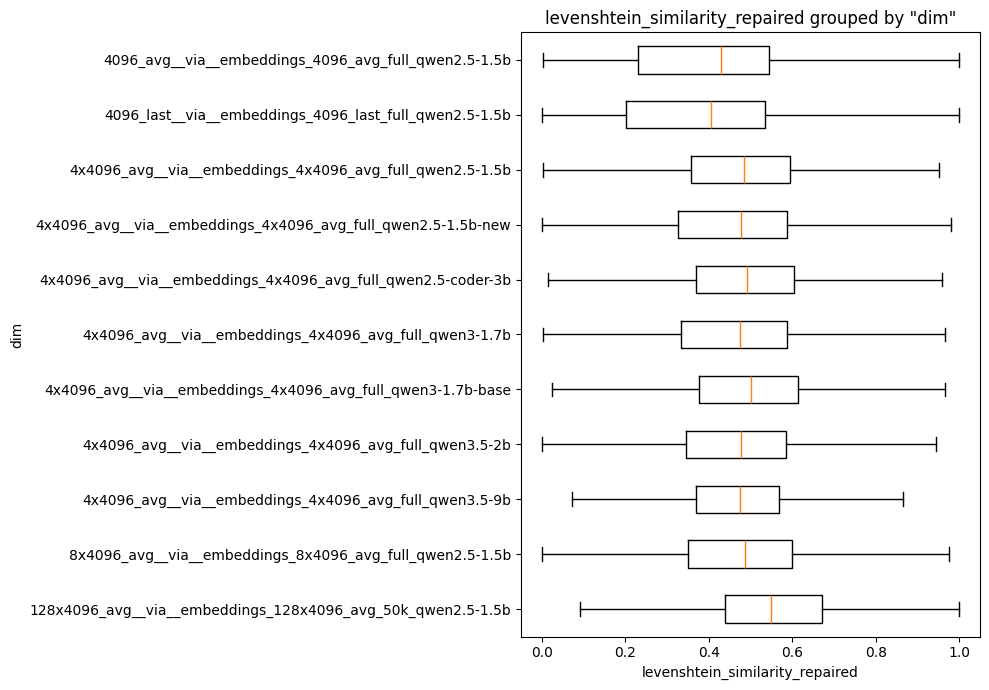

                                                                count  \
dim                                                                     
4096_avg__via__embeddings_4096_avg_full_qwen2.5-1.5b          66261.0   
4096_last__via__embeddings_4096_last_full_qwen2.5-1.5b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b      66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-1.5b-new  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen2.5-coder-3b  66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3-1.7b-base   66260.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b        66261.0   
4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b        66261.0   
8x4096_avg__via__embeddings_8x4096_avg_full_qwen2.5-1.5b      66261.0   
128x4096_avg__via__embeddings_128x4096_avg_50k_qwen2.5-1.5b   46927.0   

                                                  

In [22]:
show_stats('levenshtein_similarity')
show_stats('levenshtein_similarity_repaired')

## Order-free component metrics

`class_accuracy` and `average_bounds_iou` pair components by their position in
the flattened DFS order. Two siblings emitted in the other order score zero
twice, and a single component too many near the top shifts *every* following
pair by one. Neither says anything about the quality of the screen: position
lives in `bounds`, not in the order of the list.

The metrics below drop that pairing.

| column | what it measures |
|---|---|
| `class_unordered_recall` / `_precision` / `_f1` | class multiset overlap over the whole tree -- order and nesting ignored entirely |
| `class_level_recall` / `_precision` / `_f1` | the same overlap per tree depth -- free within a level, the depth has to be right |
| `matched_iou` | greedy best-first IoU matching of same-class components, over `max(n_pred, n_gt)` |

Recall is against the ground truth, precision against the prediction. Recall
alone would reward a model that simply emits one of every class it knows,
which is why all three are carried.

Every value is a **per-screen** score; the aggregation across screens happens
here, in the cells below. Each metric appears twice: bare for the strict parse
(unparseable prediction = 0.0) and with `_repaired` for the json_repair'd and
loop-collapsed one, the same split the columns above use.

In [ ]:
# `df` holds the report values as objects, so every order-free column is coerced
# once here rather than in each cell below. The index is kept so plot_bool_grouped()
# and show_stats() can still address "dim" as an index level.

ORDER_FREE_COLS = [
    col
    for key in UNORDERED_METRIC_KEYS
    for col in (key, f"{key}_repaired")
]


def numeric_view(columns):
    """A float-typed copy of `df[columns]`, index intact."""
    return df[columns].apply(pd.to_numeric, errors="coerce")


by_dim = df.index.get_level_values("dim")
order_free = numeric_view(ORDER_FREE_COLS)

for stat in ("mean", "median"):
    table = getattr(order_free.groupby(by_dim), stat)().rename_axis("dim")
    table = table.reindex(sorted(table.index, key=first_number_sort_key))
    print(f"=== per-screen {stat} ===")
    print(table.T.to_string(float_format=lambda v: f"{v:.4f}"))
    print()

In [ ]:
# How much of the reported score was lost to the positional pairing alone.
#
# Same predictions, same ground truth -- the only difference is whether the
# comparison insists on the DFS order. `class_unordered_recall` is the directly
# comparable counterpart to `class_accuracy`: both ask "how many of the ground
# truth's components did the prediction get right".

comparison = numeric_view(
    ["class_accuracy", "class_unordered_recall", "class_unordered_f1", "class_level_f1"]
)

plot_bool_grouped(
    comparison,
    ["class_accuracy", "class_unordered_recall", "class_level_f1"],
    by="dim",
    as_percentage=True,
    xlabel="per-screen mean (%)",
    title="Class score: positional vs. order-free vs. depth-aware (strict)",
)

# Share of screens the positional metric scores *below* the order-free one --
# i.e. screens where it is measuring the ordering, not the reconstruction.
understated = (
    comparison["class_unordered_recall"] > comparison["class_accuracy"] + 1e-9
)
share = (understated.groupby(by_dim).mean() * 100).rename("understated_%")
share = share.reindex(sorted(share.index, key=first_number_sort_key))

print("Screens where the positional pairing understates the reconstruction:")
print(share.to_string(float_format=lambda v: f"{v:6.1f} %"))

In [ ]:
# The same comparison for the bounding boxes. `average_bounds_iou` pairs by DFS
# position and divides by min(n_pred, n_gt); `matched_iou` matches same-class
# components best-first by IoU and divides by max(n_pred, n_gt), so invented and
# dropped components cost score instead of being free.

plot_bool_grouped(
    numeric_view(["average_bounds_iou", "matched_iou"]),
    ["average_bounds_iou", "matched_iou"],
    by="dim",
    as_percentage=True,
    xlabel="per-screen mean IoU (%)",
    title="Bounds IoU: positional vs. matched (strict)",
)

### Strict vs. repaired

In [ ]:
plot_bool_grouped(
    numeric_view(["class_unordered_f1", "class_unordered_f1_repaired"]),
    ["class_unordered_f1", "class_unordered_f1_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="per-screen mean (%)",
    title="Unordered Class F1: strict vs. repaired",
)

plot_bool_grouped(
    numeric_view(["class_level_f1", "class_level_f1_repaired"]),
    ["class_level_f1", "class_level_f1_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="per-screen mean (%)",
    title="Depth-Aware Class F1: strict vs. repaired",
)

plot_bool_grouped(
    numeric_view(["matched_iou", "matched_iou_repaired"]),
    ["matched_iou", "matched_iou_repaired"],
    by="dim",
    as_percentage=True,
    xlabel="per-screen mean IoU (%)",
    title="Matched Bounds IoU: strict vs. repaired",
)

### Boxplot: Unordered Class Recall / Precision / F1

In [ ]:
show_stats('class_unordered_recall')
show_stats('class_unordered_recall_repaired')
show_stats('class_unordered_precision')
show_stats('class_unordered_precision_repaired')
show_stats('class_unordered_f1')
show_stats('class_unordered_f1_repaired')

### Boxplot: Depth-Aware Class Recall / Precision / F1

In [ ]:
show_stats('class_level_recall')
show_stats('class_level_recall_repaired')
show_stats('class_level_precision')
show_stats('class_level_precision_repaired')
show_stats('class_level_f1')
show_stats('class_level_f1_repaired')

### Boxplot: Matched Bounds IoU

In [ ]:
show_stats('matched_iou')
show_stats('matched_iou_repaired')

## Plots

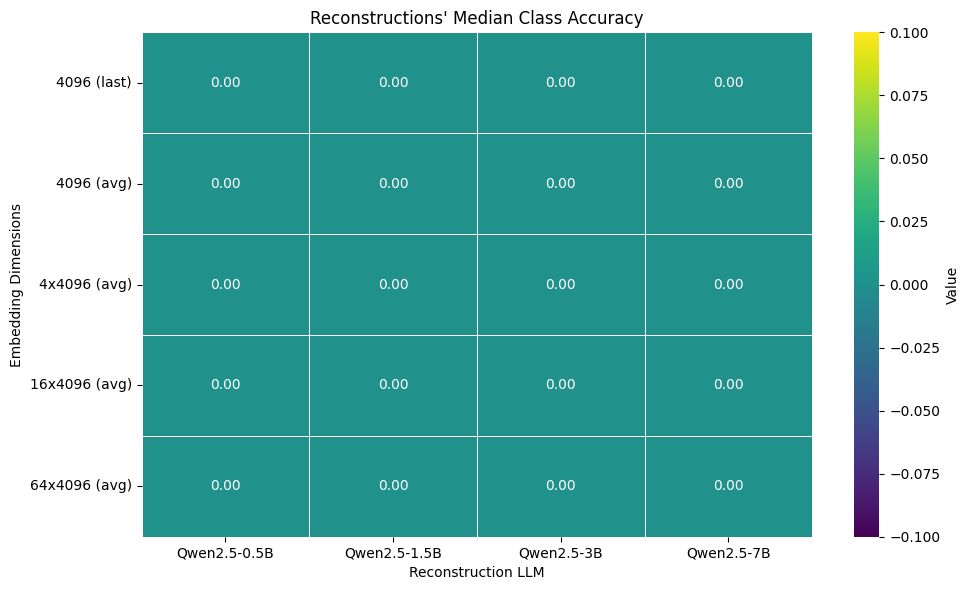

In [23]:
# Zeilen: Embedding Dimensions
# Spalten: Reconstruction LLM
values = [
    [0.00, 0.00, 0.00, 0.00],  # 4096 (last)
    [0.00, 0.00, 0.00, 0.00],  # 4096 (avg)
    [0.00, 0.00, 0.00, 0.00],  # 4x4096 (avg)
    [0.00, 0.00, 0.00, 0.00],  # 16x4096 (avg)
    [0.00, 0.00, 0.00, 0.00],  # 64x4096 (avg)
]

embedding_dimensions = [
    "4096 (last)",
    "4096 (avg)",
    "4x4096 (avg)",
    "16x4096 (avg)",
    "64x4096 (avg)",
]

reconstruction_llms = [
    "Qwen2.5-0.5B",
    "Qwen2.5-1.5B",
    "Qwen2.5-3B",
    "Qwen2.5-7B",
]

df = pd.DataFrame(
    values,
    index=embedding_dimensions,
    columns=reconstruction_llms,
)

fig, ax = plt.subplots(
    figsize=(10, 6),
    facecolor="white",
)

ax.set_facecolor("white")

heatmap = sns.heatmap(
    df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Value"},
    ax=ax,
)

heatmap.figure.axes[-1].set_facecolor("white")

ax.set_title("Reconstructions' Median Class Accuracy")
ax.set_xlabel("Reconstruction LLM")
ax.set_ylabel("Embedding Dimensions")

fig.tight_layout()

fig.savefig(
    "median_class_accuracy.pdf",
    bbox_inches="tight",
    facecolor="white",
    transparent=False,
)

fig.savefig(
    "median_class_accuracy.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    transparent=False,
)

plt.show()